# Lab 2: Metodo del sotto-gradiente
In questo laboratorio, implementeremo il metodo del sottogradiente.

In [ ]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

# generatore di numeri (pseudo)-casuali (utilizzato per riproducibilita`)
rnd_state = np.random.RandomState(12)


## Introduzione

Consideriamo il seguente problema di minimizzazione
$$
\min\limits_{x \in \mathbb{R}^d} f(x) := | x |.
$$


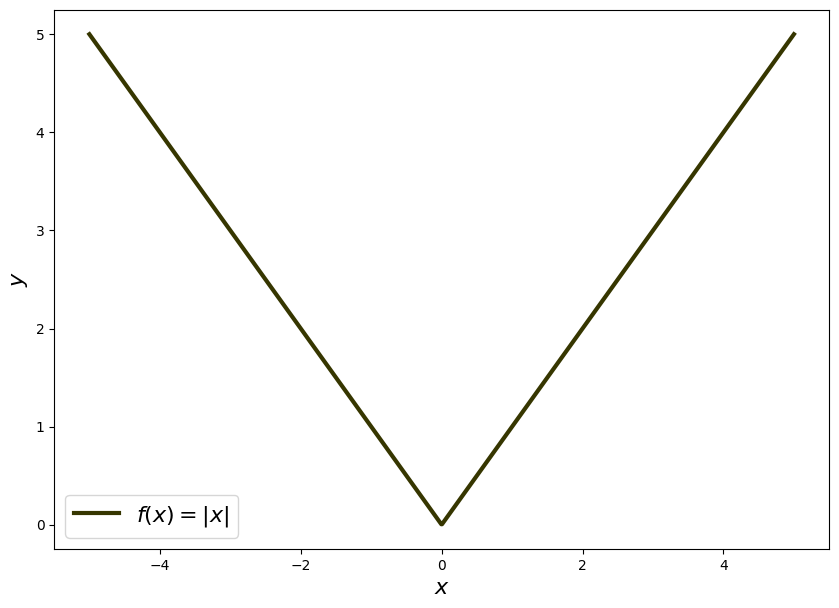

In [ ]:
def target(x):
  return abs(x) # abs calcola il valore assoluto

X = np.linspace(-5, 5, 1000) # 1000 punti in [-5, 5]
y = target(X)

fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(X, y, '-', c=[0.21, 0.21, 0.001], lw=3, label='$f(x) = |x|$')
ax.set_xlabel("$x$", fontsize=16)
ax.set_ylabel("$y$", fontsize=16)
_ = ax.legend(fontsize=16)


Dal momento che $f$ in $x = 0$ non e` differenziabile, non possiamo utilizzare gradient descent per risolvere il problema.

### Sotto-gradiente e sotto-differenziale
Per poter risolvere il problema precedente (e in generale gestire i casi in cui la funzione obiettivo non e\` liscia), introduciamo il concetto di sotto-gradiente e definiamo un algoritmo noto come ***sub-gradient descent***.

**sotto-differenziale**: data una funzione  $f : \mathbb{R}^d \to \mathbb{R}$, per ogni $x \in \mathbb{R}^d$, definiamo il sotto-differenziale $\partial f(x)$ come segue

$$
\partial f(x) := \{ g \in \mathbb{R}^d  \,|\, f(z) \geq f(x) + g^\intercal (z - x) \quad \forall z \in \mathbb{R}^d \}.
$$

Per ogni $x \in \mathbb{R}^d$, definiamo inoltre un sotto-gradiente $g$ in $x$ come e` un elemento di $\partial f(x)$.





Inoltre, e\` possibile provare che se $f$ e\` differenziabile in $x$ allora
$$
\partial f(x) = \{ \nabla f(x) \}.
$$

Riprendendo l'esempio precedente (i.e. $f(x) = |x|$) abbiamo che

$$
\partial f(x) = \left\{
  \begin{array}{ll}
    \{ 1\} & x > 0 \\
    \{ -1\} & x < 0 \\
    [-1, 1] & x = 0
    \end{array}
  \right.
$$
Quindi, un sottogradiente $g$ di $f$ in $x$ sara\`
$$
g = \left\{
  \begin{array}{ll}
    1 & x > 0 \\
    -1 & x < 0 \\
    u \in [-1, 1] & x = 0
    \end{array}
  \right.
$$
A fini illustrativi, implementiamo una funzione `sample_g(x)` che dato un `x` (float), ritorna un sottogradiente di $f(x)$

In [ ]:
def sample_g(x):
  if x != 0: # se x non e` 0 allora ritorna 1 se x > 0, -1 altrimenti
    return np.sign(x) # np.sign ritorna 1 se x > 0, -1 se x < 0 (e 0 se x = 0)
  return 2 * rnd_state.rand(1)-1 # la funzione rand(d) ritorna d valori in [0, 1)


Ora, fissato $x_0 = 0$, possiamo plottare per ogni $x$,
$$
\phi(x) := f(x_0) + g (x - x_0),
$$
verificando (empiricamente) che e` un lower-bound di $f$ (come segue dalla definizione di sotto-gradiente).


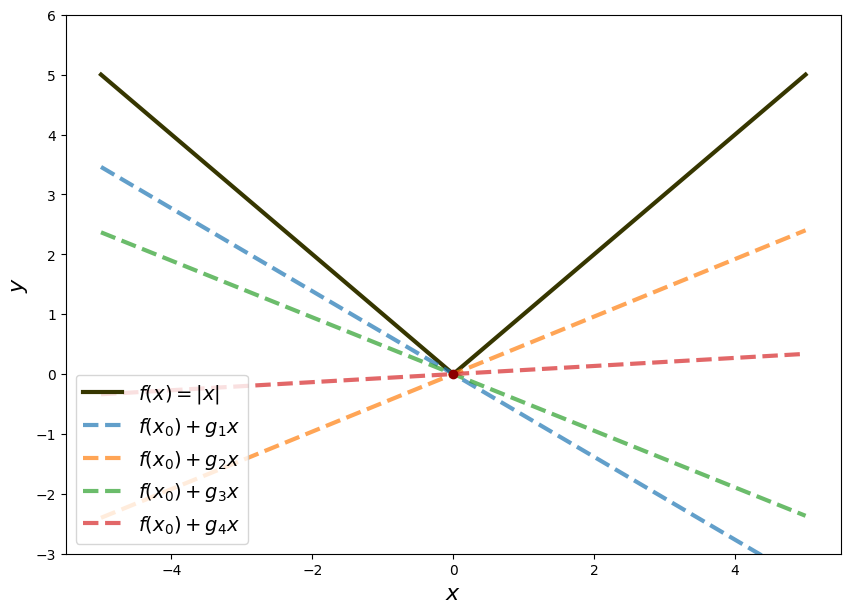

In [ ]:
x_0 = 0.0

lower_bounds = []
for i in range(4):
  # campiona 4 sotto-gradienti in x_0 e calcola [f(x_0) + g_i * (x - x_0)] per i = 1, ..., 4
  g = sample_g(x_0) # campiona un sottogradiente
  lb = [target(x_0) + g*x for x in X]  # computa phi(x) per ogni x in X (discretizzazione dello spazio)
  lower_bounds.append(lb)

fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(X, y, '-', c=[0.21, 0.21, 0.001], lw=3, label='$f(x) = |x|$')
for i, lb in enumerate(lower_bounds): # plotta le liste contenenti phi(x) per diversi sottogradienti
  ax.plot(X, lb, '--',  alpha=0.7, lw=3, label='$f(x_0) + g_{} x$'.format(i + 1))
ax.plot(0.0, 0.0, 'o', c='darkred')
ax.set_xlabel("$x$", fontsize=16)
ax.set_ylabel("$y$", fontsize=16)
ax.set_ylim([-3.0, 6.0])
_ = ax.legend(loc='lower left', fontsize=14)


### Metodo del sotto-gradiente


Dato un punto $x_0 \in \mathbb{R}^d$ e una sequenza $(\gamma_k)_{k \in \mathbb{N}}$, definiamo il metodo del sotto-gradiente come la seguente iterazione:
$$
x_{k + 1} = x_k - \gamma_k g_k \qquad \text{con} \qquad g_k \in \partial f(x_k).
$$


Il metodo del sotto-gradiente non e\` (necessariamente) un algoritmo di discesa ragione per cui si tiene traccia della migliore valutazione $f_{\text{best}}(x_k)$ trovata a time-step $k$ i.e.
$$
f_{\text{best}}(x_k) := \min\limits_{i = 0, \cdots, k} f(x_i).
$$

## Esercizio 1: Norma L1
Consideriamo ora il seguente problema. Sia $f : \mathbb{R}^2 \to \mathbb{R}$,
$$
\min\limits_{x \in \mathbb{R}^d} f(x) := 5 |x_1| + 2 |x_2|
$$


___
Funzioni che possono essere utili:
- [numpy.linalg.norm](https://numpy.org/doc/stable/reference/generated/numpy.linalg.norm.html)
- [numpy.meshgrid](https://numpy.org/doc/stable/reference/generated/numpy.meshgrid.html)
- [numpy.linspace](https://numpy.org/doc/stable/reference/generated/numpy.linspace.html)
- [numpy.random.rand](https://numpy.org/doc/stable/reference/random/generated/numpy.random.rand.html)

Text(0, 0.5, '$y$')

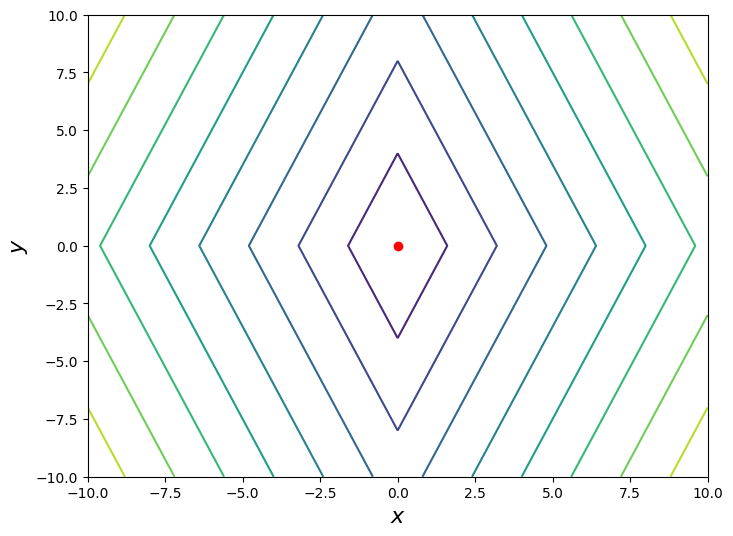

In [ ]:
x1 = np.linspace(-10,  10, 1000)
x2 = np.linspace(-10,  10, 1000)

X, Y = np.meshgrid(x1, x2)

Z =  5 * abs(X) + 2.0 * abs(Y)


fig, ax= plt.subplots(figsize=(8, 6))
ax.plot(0.0, 0.0, 'o', c='red')
ax.contour(X, Y, Z, levels = 10)
ax.set_xlabel("$x$", fontsize=16)
ax.set_ylabel("$y$", fontsize=16)



Ricordiamo che
1. se $f(x) = f_1(x_1) + f_2(x_2) + \cdots + f_m(x_m)$ con $(f_i)_{i=1}^m$ funzioni convesse, allora
$$
(\forall x \in \mathbb{R}^d) \qquad\partial f(x) = \partial f_1(x_1) \times  \cdots \times \partial f_m(x_m).
$$

2. Sia $f : \mathbb{R}^d \to \mathbb{R}$ una funzione convessa e sia $\alpha > 0$. Se definiamo
$$
h(x) := \alpha f(x),
$$
allora
$$
(\forall x \in \mathbb{R}^d) \qquad \partial h(x) = \alpha \partial f(x).
$$

Quindi riprendendo la funzione precedente, un sotto-gradiente $g$ di $f$ in $x$ sara` $g \in \mathbb{R}^2$ con
$$
g_1 = \left\{
  \begin{array}{ll}
    -5 & x < 0\\
    5 & x > 0\\
    v \in [-5, 5]
  \end{array}
  \right. \qquad
\text{e} \qquad
g_2 = \left\{
  \begin{array}{ll}
    -2 & x < 0\\
    2 & x > 0\\
    v \in [-2, 2]
  \end{array}
  \right.
$$
Dove $g_1, g_2$ sono rispettivamente la prima e la seconda entrata del vettore $g$.

Implementiamo quindi una funzione `sample_g(x)` che dato un numpy array $x$, ritorna un sottogradiente di $f$ in $x$.

In [ ]:
def target(x):
  return 5.0 *abs(x[0]) + 2.0 * abs(x[1])

def sample_g(x):
  # TODO: return un sotto-gradiente di f in x
    if x[0]!= 0:
      x1=5*np.sign(x[0])
    else:
      x1=10 * rnd_state.rand() - 5

    if x[1]!=0:
      x2=2*np.sign(x[1])
    else:
      x2=4  * rnd_state.rand() - 2

    return   np.array([x1,x2])



Ora implementiamo la funzione `subgrad_descent(x0, gamma, T, target, sample_g)` che eseguira subgradient descent per minimizzare la funzione $f$ introdotta precedentemente.

I parametri di tale funzione sono i seguenti:
- `x0`: punto iniziale (un numpy array di dimensione 2)
- `gamma`: step-size (costante)
- `T`: numero di iterationi
- `target`: funzione target (i.e. la $f$)
- `sample_g`: funzione che permette di campionare un sottogradiente

Nota che, gli ultimi due parametri ci permettono di evitare di riscrivere il codice per altre funzioni rendendo la funzione `subgrad_descent` piu` generale.

Tale funzione dovra` ritornare:
- `x`: l'ultima iterata
- `f_vals`: un numpy array contenente i valori della funzione nelle iterate
- `x_obs` : un numpy array di size $T \times 2$ contenente la traiettoria (i.e. le iterate osservate)
- `f_best` : un numpy array di size $T$ tale che in ogni entrata $k$ contiene $f_\text{best}(x_k)$

In [ ]:
def subgrad_descent(x0, gamma, T, target, sample_g):
  f_vals = np.empty(T + 1)
  f_best = np.empty(T + 1)
  x_obs = np.empty((T + 1, x0.shape[0]))
  x = x0.copy()
  f_min = target(x) # miglior f(x)
  f_vals[0] = f_min
  f_best[0] = f_min
  x_obs[0] = x.copy()

  for t in range(T):
    g = sample_g(x).flatten()
    # TODO: implementa subgradient descent
    x = x - gamma*g
    fx = target(x)
    f_vals[t + 1] = fx
    x_obs[t + 1] = x.copy()
    if f_min > fx:
      f_min = fx
    f_best[t + 1] = f_min
  return x, f_vals, x_obs, f_best


Dalla teoria, sappiamo che se consideriamo la seguente iterazione
$$
x_{k + 1} = x_k - \gamma_k g_k \qquad g_k \in \partial f(x_k)
$$
e assumiamo $f$ $L$-Lipschitz continua (e quindi $\| g\|_2 \leq L$ per ogni $g \in \partial f(x)$ in ogni $x$), abbiamo che
$$
f_{best}(x_k) - f(x^*) \leq \frac{\| x_0 - x^* \|_2^2 + L^2 \sum\limits_{i=0}^k \gamma_i^2}{2 \sum\limits_{i=0}^k \gamma_i}.
$$
Nello specifico, se consideriamo $\gamma_i = \gamma$ per $i = 1,\cdots$ con $\gamma >0$,
$$
f_{best}(x_k) - f(x^*) \leq \frac{\| x_0 - x^* \|_2^2 + L^2 \gamma^2 k}{2 \gamma k}.
$$
Quindi per $k \to +\infty$, il termine a destra della disuguaglianza converge a $L^2 \gamma/2$.

Eseguendo subgradient descent con diversi valori di $\gamma$, possiamo osservare come lo step-size impatta il risultato

In [ ]:
x0 = np.array([1.0, 1.0])
T = 100

gammas = [0.15,0.1, 0.05,0.01, 0.005]
function_values = np.empty((len(gammas), T + 1), dtype=np.float32)
best_function_values = np.empty((len(gammas), T + 1), dtype=np.float32)


# TODO: esegui subgradient descent per i diversi gamma e salva f_vals e f_best nei due array definiti sopra
for i in range(len(gammas)):
  x, f_vals, x_obs, f_best= subgrad_descent(x0, gammas[i], T, target, sample_g)
  function_values[i]=f_vals
  best_function_values[i]=f_best



Text(0.5, 1.0, 'Best Function Values')

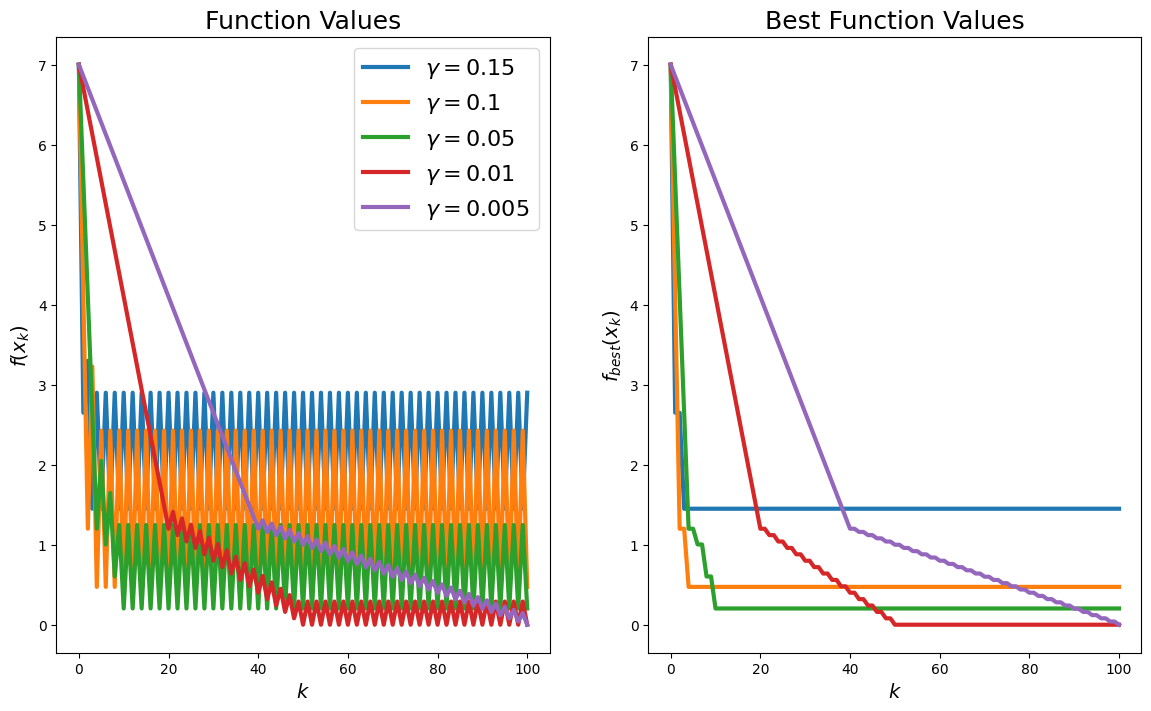

In [ ]:
fig, (ax1, ax2)= plt.subplots(1, 2, figsize=(14, 8))
for (i, gamma) in enumerate(gammas):
  ax1.plot(range(function_values[i].shape[0]), function_values[i],'-', lw=3, label="$\gamma = {}$".format(gamma))
  ax2.plot(range(best_function_values[i].shape[0]), best_function_values[i],'-', lw=3, label="$\gamma = {}$".format(gamma))
ax1.legend(fontsize=16)
ax1.set_xlabel("$k$", fontsize=14)
ax1.set_ylabel("$f(x_k)$", fontsize=14)
ax2.set_xlabel("$k$", fontsize=14)
ax2.set_ylabel("$f_{best}(x_k)$", fontsize=14)

ax1.set_title("Function Values", fontsize=18)
ax2.set_title("Best Function Values", fontsize=18)


## plot traiettoria subgradiente




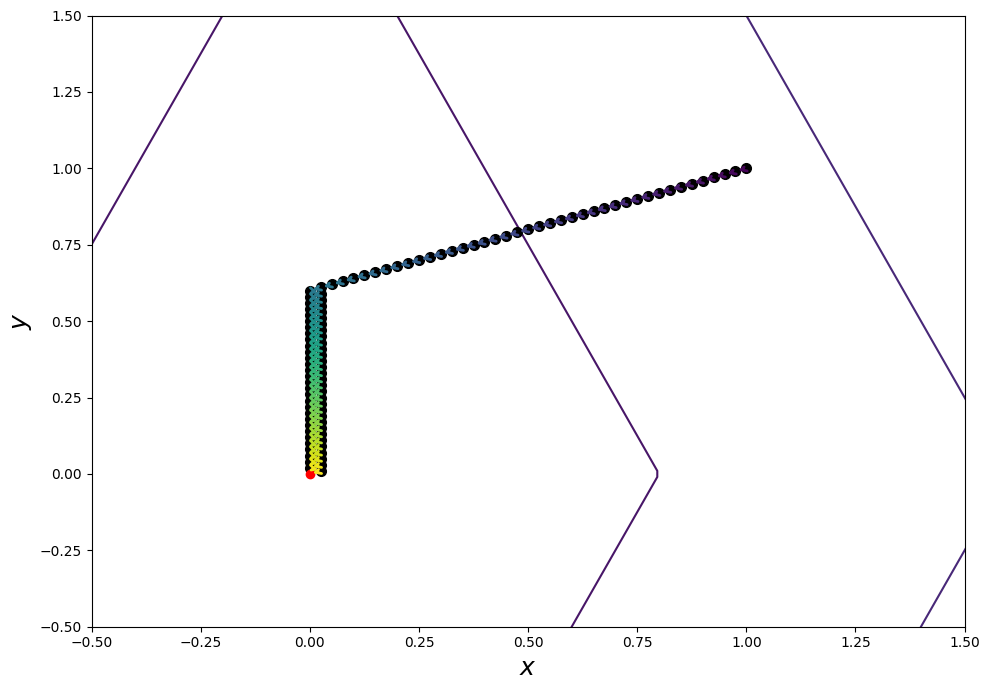

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

#PLOTTARE CON 20 ITERAZIONI E GAMMA NON TROPPO ALTO/BASSO TIPO 0.03

fig, ax = plt.subplots(1, 1, figsize=(10, 7))
ax.contour(X, Y, Z, levels=20)

step_limit =x_obs.shape[0]
x_prev = x_obs[0]
for i in range(1, step_limit):
    x = np.clip(x_obs[i], [-10, -10], [10, 10])
    color = plt.cm.viridis(i / step_limit)
    ax.plot(x_prev[0], x_prev[1], 'o', c='black', ms=7)
    ax.annotate("", xy=(x[0], x[1]), xytext=(x_prev[0], x_prev[1]), arrowprops=dict(arrowstyle='->', ls='--', lw=2.0, color=color))
    x_prev = x

ax.plot(0.0, 0.0, 'o', c='red')
ax.set_xlabel("$x$", fontsize=18)
ax.set_ylabel("$y$", fontsize=18)

ax.set_xlim([-0.5, 1.5])
ax.set_ylim([-0.5, 1.5])

fig.tight_layout()
plt.show()



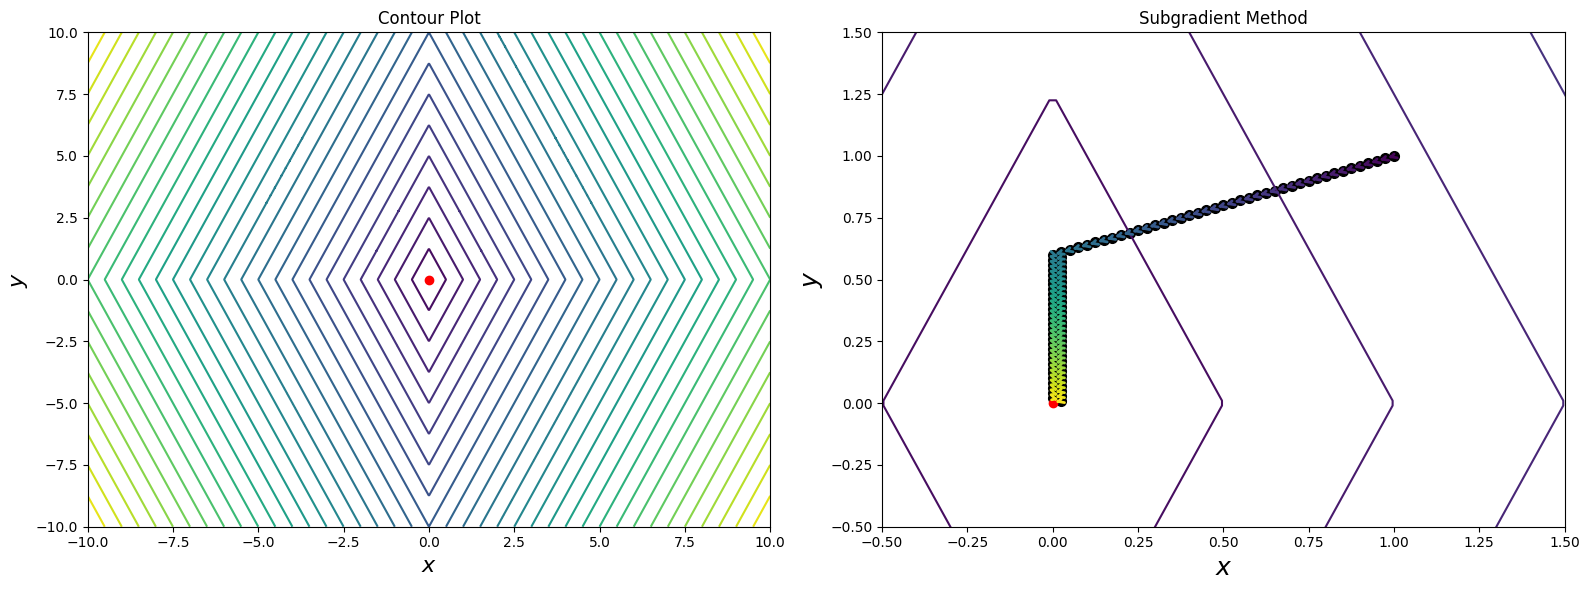

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


x1 = np.linspace(-10, 10, 1000)
x2 = np.linspace(-10, 10, 1000)
X, Y = np.meshgrid(x1, x2)
Z = 5 * abs(X) + 2.0 * abs(Y)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))


ax1.plot(0.0, 0.0, 'o', c='red')
ax1.contour(X, Y, Z, levels=30)
ax1.set_xlabel("$x$", fontsize=16)
ax1.set_ylabel("$y$", fontsize=16)
ax1.set_title('Contour Plot')


step_limit = x_obs.shape[0]
x_prev = x_obs[0]
for i in range(1, step_limit):
    x = np.clip(x_obs[i], [-10, -10], [10, 10])
    color = plt.cm.viridis(i / step_limit)
    ax2.plot(x_prev[0], x_prev[1], 'o', c='black', ms=7)
    ax2.annotate("", xy=(x[0], x[1]), xytext=(x_prev[0], x_prev[1]), arrowprops=dict(arrowstyle='->', ls='--', lw=2.0, color=color))
    x_prev = x

ax2.plot(0.0, 0.0, 'o', c='red')
ax2.contour(X, Y, Z, levels=30)
ax2.set_xlabel("$x$", fontsize=18)
ax2.set_ylabel("$y$", fontsize=18)
ax2.set_title('Subgradient Method')


ax2.set_xlim([-0.5, 1.5])
ax2.set_ylim([-0.5, 1.5])

fig.tight_layout()
plt.show()



## Esercizio 2: Piece-wise linear minimization
Consideriamo ora $f: \mathbb{R}^{10} \to \mathbb{R}$
$$
f(x) := \max_{i = 1,\cdots, m} (a_i^\intercal x + b_i)
$$

In [ ]:
m = 100
d = 20

A = rnd_state.randn(d, m)
b  = rnd_state.randn(m)

In [ ]:

def target(x):
  values = A.T.dot(x) + b
  return np.max(values)


In questo caso, un sotto-gradiente $g$ di $f$ in $x$ e` $a_j$ tale che
$$
j \in \arg\max\limits_{i = 1, \cdots, m} a_i^\intercal x + b_i
$$
Quindi, per campionare un sottogradiente, possiamo:
1. calcolare $a_i^\intercal x + b_i$ per  $i = 1, \cdots, m$
2. isolare gli $a_j \in \arg\max a_i^\intercal x + b_i$
3. campionarne uno a caso

Implementiamo quindi una funzione `sample_g(x)` che svolge queste tre operazioni.

___
Funzioni utili:
- [np.argwhere](https://numpy.org/doc/stable/reference/generated/numpy.argwhere.html)
- [np.random.choice](https://numpy.org/doc/stable/reference/random/generated/numpy.random.choice.html)
- [np.ndarray.flatten](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.flatten.html)

In [ ]:
def sample_g(x):
  # TODO: campiona un sottogradiente di f in x

    values = A.T.dot(x) + b
    # Trova gli indici dei massimi valori
    max_indices = np.argwhere(values == np.max(values)).flatten()
    # Campiona uno degli indici casualmente
    sampled_index = np.random.choice(max_indices)
    # Restituisce il sotto-gradiente corrispondente
    return A[:, sampled_index]




In [ ]:
def subgrad_descent(x0, gamma, T, target, sample_g):
  f_vals = np.empty(T + 1)
  f_best = np.empty(T + 1)
  x_obs = np.empty((T + 1, x0.shape[0]))
  x = x0.copy()
  f_min = target(x) # miglior f(x)
  f_vals[0] = f_min
  f_best[0] = f_min
  x_obs[0] = x.copy()

  for t in range(T):
    g = sample_g(x).flatten()
    # TODO: implementa subgradient descent
    x = x - gamma*g
    fx = target(x)
    f_vals[t + 1] = fx
    x_obs[t + 1] = x.copy()
    if f_min > fx:
      f_min = fx
    f_best[t + 1] = f_min
  return x, f_vals, x_obs, f_best


Ora possiamo utilizzare la funzione `subgrad_descent` implementata precedentemente per minimizzare $f$

In [ ]:
gammas = [0.15, 0.05, 0.1, 0.01, 0.005]
x0 = np.zeros(d)
T = 500

function_values = np.empty((len(gammas), T + 1), dtype=np.float32)
best_function_values = np.empty((len(gammas), T + 1), dtype=np.float32)


# TODO: esegui subgradient descent per i diversi gamma e salva f_vals e f_best nei due array definiti sopra
for i in range(len(gammas)):
  x, f_vals, x_obs, f_best= subgrad_descent(x0, gammas[i], T, target, sample_g)
  function_values[i]=f_vals
  best_function_values[i]=f_best

Text(0.5, 1.0, 'Best Function Values')

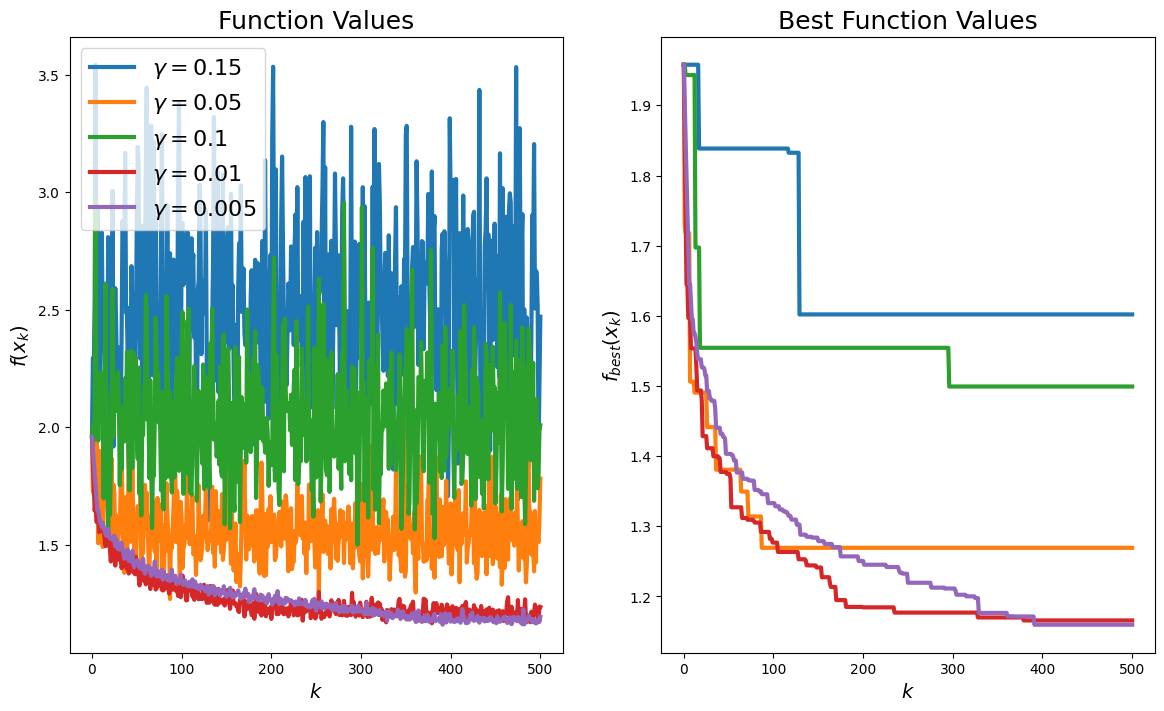

In [ ]:
# TODO: plotta i function values e i valori di f_best

fig, (ax1, ax2)= plt.subplots(1, 2, figsize=(14, 8))
for (i, gamma) in enumerate(gammas):
  ax1.plot(range(function_values[i].shape[0]), function_values[i],'-', lw=3, label="$\gamma = {}$".format(gamma))
  ax2.plot(range(best_function_values[i].shape[0]), best_function_values[i],'-', lw=3, label="$\gamma = {}$".format(gamma))
ax1.legend(fontsize=16)
ax1.set_xlabel("$k$", fontsize=14)
ax1.set_ylabel("$f(x_k)$", fontsize=14)
ax2.set_xlabel("$k$", fontsize=14)
ax2.set_ylabel("$f_{best}(x_k)$", fontsize=14)

ax1.set_title("Function Values", fontsize=18)
ax2.set_title("Best Function Values", fontsize=18)

### Step-size:
Come abbiamo potuto osservare, con step-size costante $f_{best}(x_k) - f(x^*)$ non convergenza a $0$. Come indicato nella teoria, ci sono diversi modi per fissare il passo in subgradient descent. In questa parte ci concentreremo su i seguenti step-size:
- Costant $\gamma_k = \gamma$.
$$
f_{best}(x_k) - f(x^*) \leq \frac{\| x_0 - x^* \|_2^2 + L^2 \gamma^2 k}{2 \gamma k}.
$$
- Constant Step-length: $\gamma_k = \gamma / \| g_k \|_2$
$$
f_{best}(x_k) - f(x^*) \leq \frac{\| x_0 - x^* \|_2^2 +  \gamma^2 k}{2 \gamma k / L}.
$$
- Monroe: $\gamma_k \not\in \ell^1$ e $\gamma_k^2 \in \ell^1$. Con questo step size (e.g. $\gamma_k = \gamma k^{- \theta}$ con $1 \geq \theta > 1/2$), $f_{best}(x_k) - f(x^*)$ converge a zero.


Per poter confrontare (e utilizzare) i diversi step-size, dobbiamo modificare la funzione `subgrad_descent` dato che al momento supporta unicamente step-size costante.

La funzione, quindi, si aspettera` i seguenti parameteri
```
subgrad_descent(x0, gamma, T, target, sample_g)
```
Dove `gamma` dovra` essere una funzione che prende due parametri
- `k`: l'iterazione corrente
- `g_k` : il sottogradiente campionato


Per semplificare i confronti implementiamo anche una funzione `build_stepsize(stepsize_type, gamma)` che ritorna la funzione $\gamma$ desiderata. Tale funzione prende i seguenti parametri
- `stepsize_type`: una stringa. Nello specifico se
  - `stepsize_type = 'constant'` : ritorna la funzione rappresentante lo stepsize costante.
  - `stepsize_type = 'const_steplength'` : ritorna la funzione rappresentante $\gamma_k = \gamma / \| g_k \|_2$
  - qualunque altro valore : ritorna uno stepsize che soddisfa le condizioni di Monroe
- `gamma` : costante (positiva).

In [ ]:
def build_stepsize(stepsize_type, gamma):

  def constant_stepsize(g_k, k):
    return gamma

  def constant_step_length(g_k, k):
    # TODO: return gamma / | g_k |
    return gamma/np.linalg.norm(g_k)

  def monroe_stepsize(g_k, k):
    # TODO: return gamma / sqrt(k)
    return gamma/np.sqrt(k)

  if stepsize_type == 'constant':
    return constant_stepsize
  elif stepsize_type == 'const_steplength':
    return constant_step_length
  return monroe_stepsize

Modifichiamo ora il codice per subgradient descent in modo da supportare una funzione per stepsize. Nello specifico la funzione `subgrad_descent` avra` la seguente definizione
```
subgrad_descent(x0, stepsize, T, target, sample_g)
```
dove `stepsize` e` una funzione che computa il passo.

In [ ]:
def subgrad_descent(x0, stepsize, T, target, sample_g):
  f_vals = np.empty(T + 1)
  f_best = np.empty(T + 1)
  x_obs = np.empty((T + 1, x0.shape[0]))
  x = x0.copy()
  f_min = target(x) # miglior f(x)
  f_vals[0] = f_min
  f_best[0] = f_min
  x_obs[0] = x.copy()

  for t in range(1, T + 1):
    g = sample_g(x).flatten()
    # TODO: computa lo stepsize
    gamma = stepsize(g,t)
    # TODO: aggiorna x computando l'iterata di subgradient descent
    x = x -gamma*g
    fx = target(x)
    f_vals[t] = fx
    x_obs[t] = x.copy()
    if f_min > fx:
      f_min = fx
    f_best[t] = f_min
  return x, f_vals, x_obs, f_best


Confronta le prestazioni di subgradient descent usando passo **costante** considerando diversi valori di $\gamma$.

In [ ]:
gammas = [0.4, 0.1, 0.05, 0.01]

f_vals = []
f_bests = []

T = 1000
x0 = np.ones(d)
# TODO: esegui subgrad descent con step size costante e salva i function values e i f_best(x) nelle due list
for gamma in gammas:
  stepsize_fun = build_stepsize('constant', gamma)
  _, fv, _, fb = subgrad_descent(x0, stepsize_fun, T, target, sample_g)
  f_vals.append(fv)
  f_bests.append(fb)



Text(0.5, 0.98, 'Constant')

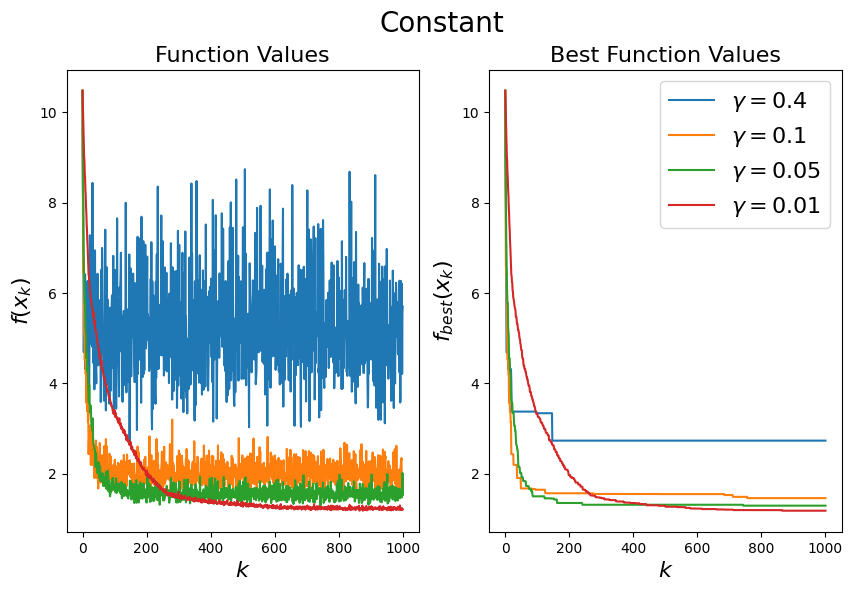

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))
for (i, gamma) in enumerate(gammas):
  ax1.plot(range(len(f_vals[i])), f_vals[i], '-', label="$\gamma = {}$".format(gamma))
  ax2.plot(range(len(f_bests[i])), f_bests[i], '-', label="$\gamma = {}$".format(gamma))

ax1.set_xlabel("$k$", fontsize=16)
ax2.set_xlabel("$k$", fontsize=16)
ax1.set_ylabel("$f(x_k)$", fontsize=16)
ax2.set_ylabel("$f_{best}(x_k)$", fontsize=16)
ax2.legend(fontsize=16)
ax1.set_title("Function Values", fontsize=16)
ax2.set_title("Best Function Values", fontsize=16)

fig.suptitle("Constant", fontsize=20)


Ripeti la stessa procedura usando lo stepsize $\gamma_k = \gamma / \| g_k \|_2$

In [ ]:
gammas = [0.4, 0.1, 0.05, 0.01]

f_vals = []
f_bests = []
x0 = np.ones(d)
T = 1000

for gamma in gammas:
  stepsize_fun = build_stepsize('const_steplength', gamma)
  _, fv, _, fb = subgrad_descent(x0, stepsize_fun, T, target, sample_g)
  f_vals.append(fv)
  f_bests.append(fb)



Text(0.5, 0.98, 'Constant Steplength')

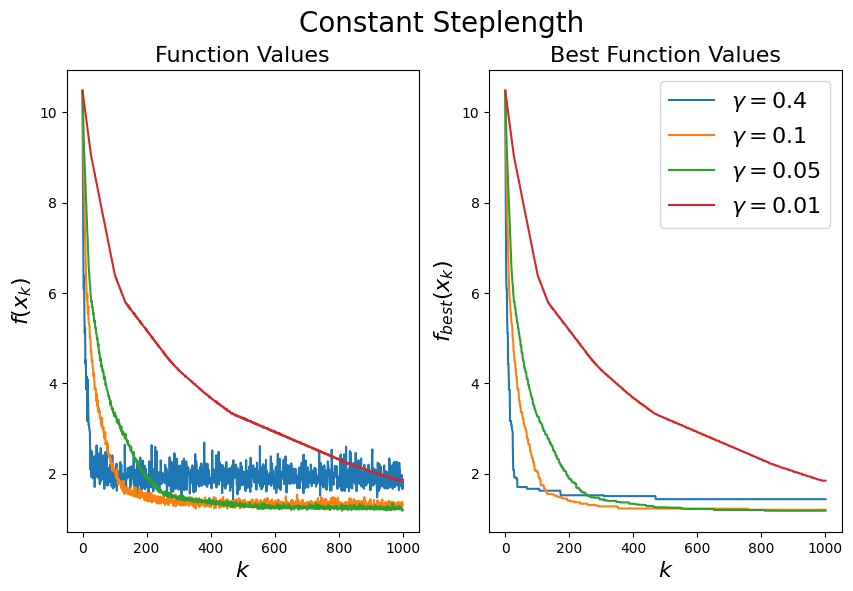

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))
for (i, gamma) in enumerate(gammas):
  ax1.plot(range(len(f_vals[i])), f_vals[i], '-', label="$\gamma = {}$".format(gamma))
  ax2.plot(range(len(f_bests[i])), f_bests[i], '-', label="$\gamma = {}$".format(gamma))

ax1.set_xlabel("$k$", fontsize=16)
ax2.set_xlabel("$k$", fontsize=16)
ax1.set_ylabel("$f(x_k)$", fontsize=16)
ax2.set_ylabel("$f_{best}(x_k)$", fontsize=16)
ax2.legend(fontsize=16)
ax1.set_title("Function Values", fontsize=16)
ax2.set_title("Best Function Values", fontsize=16)

fig.suptitle("Constant Steplength", fontsize=20)


Ripeti la stessa procedura usando Monroe stepsize

In [ ]:
# TODO: Inserisci il tuo codice qui
gammas = [0.4, 0.1, 0.05, 0.01]

f_vals = []
f_bests = []
x0 = np.ones(d)
T = 1000

for gamma in gammas:
  stepsize_fun = build_stepsize('monroe', gamma)
  _, fv, _, fb = subgrad_descent(x0, stepsize_fun, T, target, sample_g)
  f_vals.append(fv)
  f_bests.append(fb)

Text(0.5, 0.98, 'Monroe')

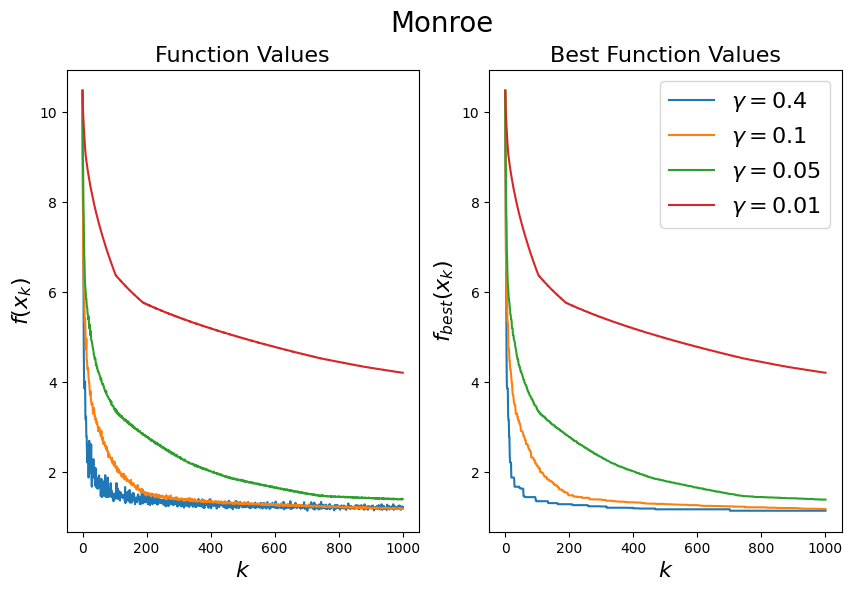

In [ ]:
# TODO: plotta i risultati
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))
for (i, gamma) in enumerate(gammas):
  ax1.plot(range(len(f_vals[i])), f_vals[i], '-', label="$\gamma = {}$".format(gamma))
  ax2.plot(range(len(f_bests[i])), f_bests[i], '-', label="$\gamma = {}$".format(gamma))

ax1.set_xlabel("$k$", fontsize=16)
ax2.set_xlabel("$k$", fontsize=16)
ax1.set_ylabel("$f(x_k)$", fontsize=16)
ax2.set_ylabel("$f_{best}(x_k)$", fontsize=16)
ax2.legend(fontsize=16)
ax1.set_title("Function Values", fontsize=16)
ax2.set_title("Best Function Values", fontsize=16)

fig.suptitle("Monroe", fontsize=20)

Ora fissa una costante $\gamma > 0$ e confronta i diversi stepsize

In [ ]:
gamma = 0.01

f_vals = []
f_bests = []
x0 = np.ones(d)
T = 10000

for stype in ['constant', 'const_steplength', 'monroe']:
  stepsize_fun = build_stepsize(stype, gamma) # TODO: usa la build_stepsize
  _, fv, _, fb = subgrad_descent(x0, stepsize_fun, T, target, sample_g) # TODO: esegui subgrad descent
  f_vals.append(fv)
  f_bests.append(fb)



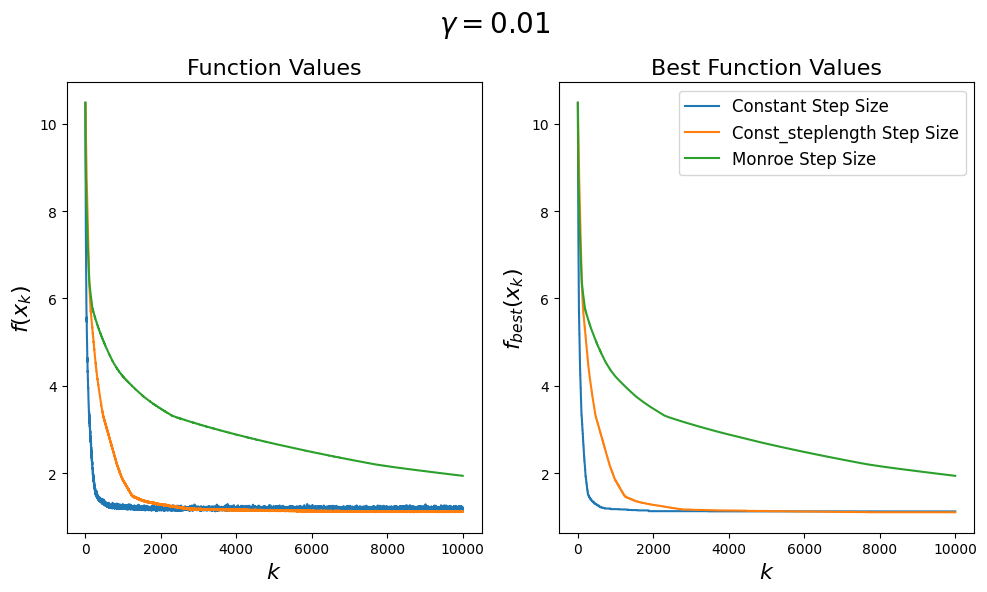

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

for i, stype in enumerate(['constant', 'const_steplength', 'monroe']):
    ax1.plot(range(len(f_vals[i])), f_vals[i], '-', label=f"{stype.capitalize()} Step Size")
    ax2.plot(range(len(f_bests[i])), f_bests[i], '-', label=f"{stype.capitalize()} Step Size")

ax1.set_xlabel("$k$", fontsize=16)
ax2.set_xlabel("$k$", fontsize=16)
ax1.set_ylabel("$f(x_k)$", fontsize=16)
ax2.set_ylabel("$f_{best}(x_k)$", fontsize=16)
ax2.legend(fontsize=12)
ax1.set_title("Function Values", fontsize=16)
ax2.set_title("Best Function Values", fontsize=16)
fig.suptitle("$\gamma = {}$".format(gamma),  fontsize=20)
plt.tight_layout()
plt.show()

## Polyak Stepsize [Opzionale]
In alcuni problemi, oltre al gradiente, abbiamo accesso all'informazione del minimo globale (i.e. e` noto $\min f$ e vogliamo trovare $x \in \arg\min f$).

In questo setting, possiamo sfruttare quest'informazione per la scelta del passo.

**Polyak stepsize**: sia $f_{min} := \min\limits_{x \in \mathbb{R}^d} f(x)$, definiamo
$$
\gamma_k = \frac{f(x_k) - f_{min}}{\| g_k \|_2^2}
$$

Tuttavia se consideriamo il problema di minimizzazione precedente, non abbiamo l'informazione del minimo. In tal caso, possiamo approssimare il Polyak stepsize come segue

$$
\gamma_k = \frac{f(x_k) - f_{best}(x_k) + \alpha_k}{\| g_k \|_2^2}
$$

con $\alpha_k \in \ell^1$

Nota che dobbiamo (di nuovo) estendere il codice di `subgrad_descent`. Nello specifico la funzione stepsize dovra` prendere come parametro anche l'iterata corrente $x_k$.

Quindi la funzione sara\` definita come `subgrad_descent(x0, stepsize, T, target, sample_g)` dove `stepsize` sara` a sua volta una funzione definita come segue
```
stepsize(fx, fx_best, g, k)
```
dove
- `fx` e` $f(x_k)$
- `fx_best` e` $f_{best}(x_k)$
- `g` e` il sottogradiente campionato
- `k` e` l'iterazione corrente


In [ ]:
def subgrad_descent(x0, stepsize, T, target, sample_g):
  f_vals = np.empty(T + 1)
  f_best = np.empty(T + 1)
  x_obs = np.empty((T + 1, x0.shape[0]))
  x = x0.copy()
  f_min = target(x) # miglior f(x)
  f_vals[0] = f_min
  f_best[0] = f_min
  x_obs[0] = x.copy()

  for t in range(1, T + 1):
    g = sample_g(x).flatten()
    # TODO: computa lo stepsize
    gamma = stepsize(f_vals[t], f_best[t], g,t)
    # TODO: aggiorna x computando l'iterata di subgradient descent
    x = x - gamma * g
    fx = target(x)
    f_vals[t] = fx
    x_obs[t] = x.copy()
    if f_min > fx:
      f_min = fx
    f_best[t] = f_min
  return x, f_vals, x_obs, f_best


Implementa il Polyak stepsize e confrontalo con altri stepsize

In [ ]:

def polyak_stepsize(fx, f_best, g, t):
  alpha_k = 20 / (10 + t)
  # TODO: return polyak stepsize (ricorda che f_min = 0) %perchè?
  return (fx-f_best+alpha_k)/(np.linalg.norm(g)**2)

def monroe_stepsize(fx, f_best, g, t):
  return 0.1 / np.sqrt(t)

def constant_steplength(fx, f_best, g, t):
  return 0.1/(np.linalg.norm(g))

def constant_stepsize(fx, f_best, g, t):
  return 0.1


In [ ]:
T = 1000

f_values = []
f_bsts = []

for step_f in [constant_stepsize, constant_steplength, monroe_stepsize, polyak_stepsize]:
  x0 = np.zeros(d)
  # TODO: esegui subgradient descent
  x, f_vals, x_obs, f_best = subgrad_descent(x0, step_f, T, target, sample_g)
  f_values.append(f_vals)
  f_bsts.append(f_best)



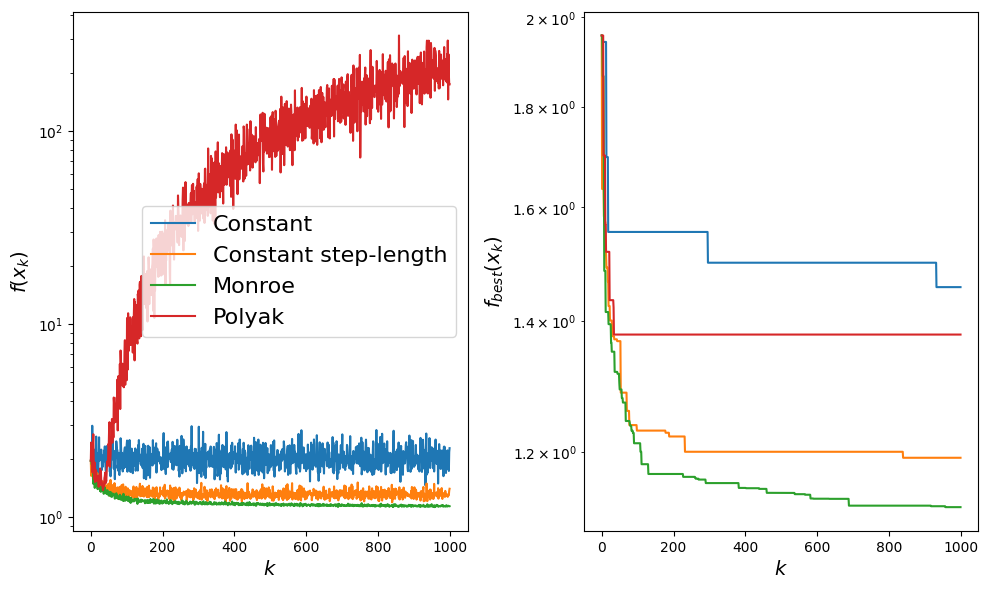

In [ ]:
labels = ['Constant','Constant step-length', 'Monroe', 'Polyak']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))
for i in range(len([constant_stepsize, constant_steplength, monroe_stepsize, polyak_stepsize])):
  ax1.plot(range(f_values[i].shape[0]), f_values[i], '-', label=labels[i])
  ax2.plot(range(f_bsts[i].shape[0]), f_bsts[i], '-', label=labels[i])
ax1.set_yscale("log")
ax2.set_yscale("log")
ax1.set_ylabel("$f(x_k)$", fontsize=14)
ax2.set_ylabel("$f_{best}(x_k)$", fontsize=14)
ax1.set_xlabel("$k$", fontsize=14)
ax2.set_xlabel("$k$", fontsize=14)
fig.tight_layout()
ax1.legend(fontsize=16)